## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Agar grafik lebih rapi
sns.set(style="whitegrid") 
#202431029_Jonathan Juan Setyanto

# EDA

## Baca Dataset

In [2]:
# Baca dataset
df = pd.read_csv("01_heart_disease.csv")

# Menampilkan 5 data teratas
df.head()
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Descriptive Analysis

In [3]:
# Info dataset: jumlah baris, kolom, tipe data, null
df.info()
#202431029_Jonathan Juan Setyanto

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [4]:
# statistik deskriptif untuk semua kolom
df.describe(include="all")
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918,918,918.000000,918.000000,918.000000,918,918.000000,918,918.000000,918,918.000000
unique,NaN,2,4,NaN,NaN,NaN,3,NaN,2,NaN,3,NaN
top,NaN,M,ASY,NaN,NaN,NaN,Normal,NaN,N,NaN,Flat,NaN
freq,NaN,725,496,NaN,NaN,NaN,552,NaN,547,NaN,460,NaN
mean,53.510893,NaN,NaN,132.396514,198.799564,0.233115,NaN,136.809368,NaN,0.887364,NaN,0.553377
std,9.432617,NaN,NaN,18.514154,109.384145,0.423046,NaN,25.460334,NaN,1.066570,NaN,0.497414
min,28.000000,NaN,NaN,0.000000,0.000000,0.000000,NaN,60.000000,NaN,-2.600000,NaN,0.000000
25%,47.000000,NaN,NaN,120.000000,173.250000,0.000000,NaN,120.000000,NaN,0.000000,NaN,0.000000
50%,54.000000,NaN,NaN,130.000000,223.000000,0.000000,NaN,138.000000,NaN,0.600000,NaN,1.000000
75%,60.000000,NaN,NaN,140.000000,267.000000,0.000000,NaN,156.000000,NaN,1.500000,NaN,1.000000


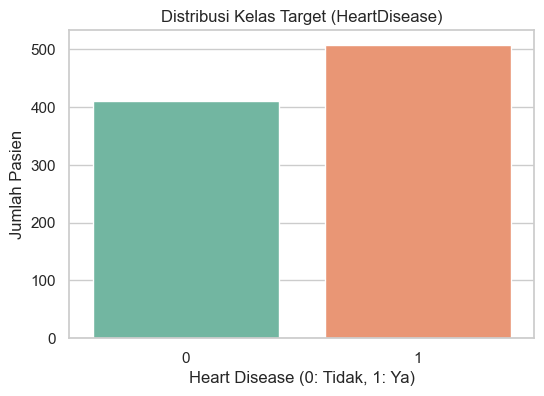

In [5]:
# statistik deskriptif untuk semua kolom 
df.describe(include="all")

# Distribusi variabel target (HeartDisease: 0 = Negatif, 1 = Positif)
plt.figure(figsize=(6, 4))
sns.countplot(x="HeartDisease", data=df, hue="HeartDisease", palette="Set2", legend=False)
plt.title("Distribusi Kelas Target (HeartDisease)")
plt.xlabel("Heart Disease (0: Tidak, 1: Ya)")
plt.ylabel("Jumlah Pasien")
plt.show()
#202431029_Jonathan Juan Setyanto

## Adjustment of Variable 

In [6]:
# Daftar kolom kategorikal pada dataset Heart Disease
categorical_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]

# Mengubah tipe data ke category
for col in categorical_cols:
    df[col] = df[col].astype("category")

df.dtypes
#202431029_Jonathan Juan Setyanto

Age                  int64
Sex               category
ChestPainType     category
RestingBP            int64
Cholesterol          int64
FastingBS         category
RestingECG        category
MaxHR                int64
ExerciseAngina    category
Oldpeak            float64
ST_Slope          category
HeartDisease         int64
dtype: object

## Detection and Treatment of Missing Data

In [7]:
# Cek jumlah nilai hilang (missing value) per kolom
print("Jumlah Missing Values:")
print(df.isnull().sum())
#202431029_Jonathan Juan Setyanto

Jumlah Missing Values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


## Identification of Atypical Data (Outliers)

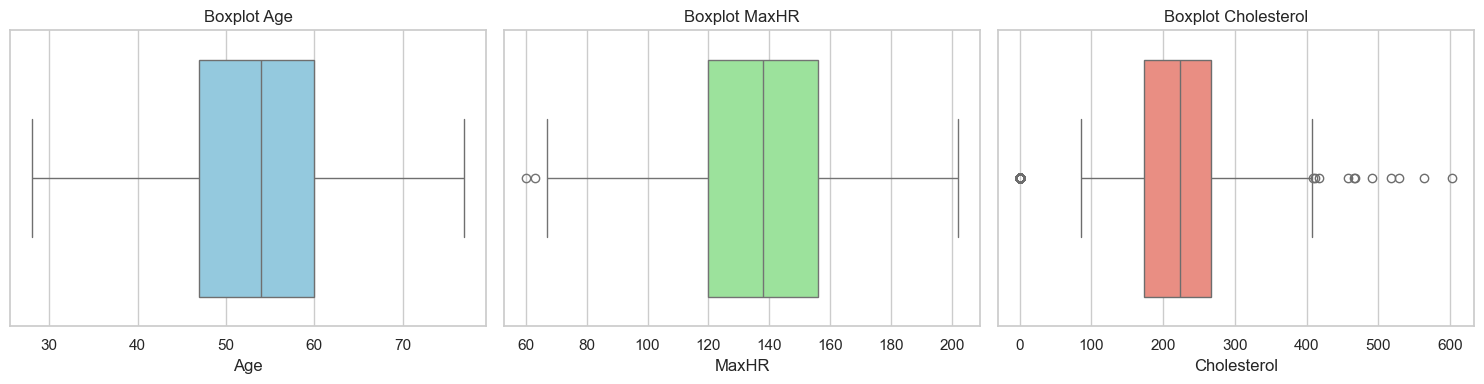

In [8]:
# Visualisasi boxplot untuk variabel numerik (Age, MaxHR, RestingBP, Cholesterol, Oldpeak)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df["Age"], ax=axes[0], color="skyblue")
axes[0].set_title("Boxplot Age")

sns.boxplot(x=df["MaxHR"], ax=axes[1], color="lightgreen")
axes[1].set_title("Boxplot MaxHR")

sns.boxplot(x=df["Cholesterol"], ax=axes[2], color="salmon")
axes[2].set_title("Boxplot Cholesterol")

plt.tight_layout()
plt.show()
#202431029_Jonathan Juan Setyanto

In [9]:
# Deteksi outlier pada kolom Age menggunakan Metode IQR
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[(df["Age"] < Q1 - 1.5 * IQR) | (df["Age"] > Q3 + 1.5 * IQR)]
print("Jumlah outlier pada kolom Age:", len(outliers))
#202431029_Jonathan Juan Setyanto

Jumlah outlier pada kolom Age: 0


## Correlation of Variables

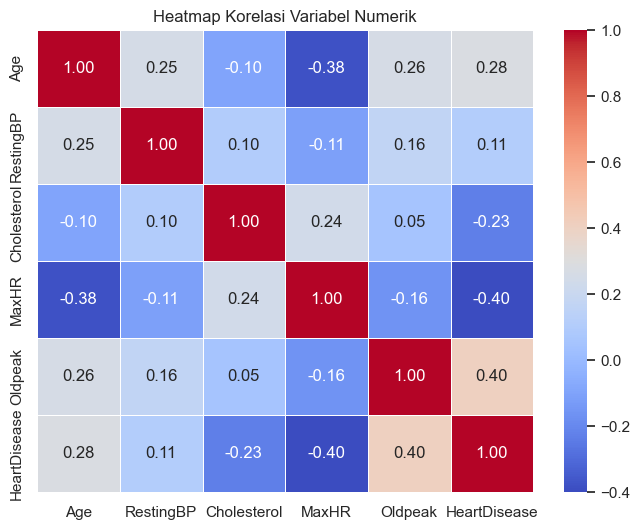

In [10]:
# Filter variabel numerik saja
numeric_df = df.select_dtypes(include=["int64", "float64"])

# Heatmap korelasi antar variabel numerik
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Variabel Numerik")
plt.show()
#202431029_Jonathan Juan Setyanto

C:\Users\jjset\AppData\Local\Temp\ipykernel_34456\3567742284.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="HeartDisease", y="Age", data=df, palette="Set3")


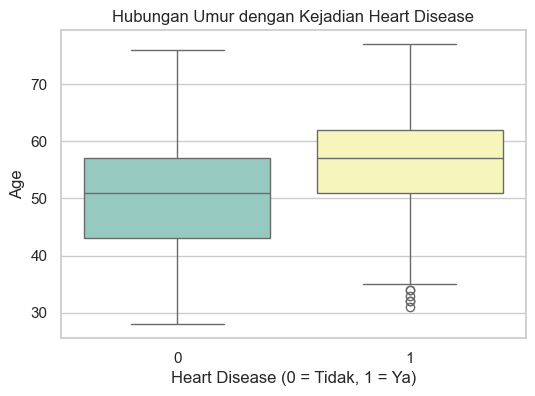

In [11]:
# Hubungan Umur (Age) dengan kejadian Penyakit Jantung (HeartDisease)
plt.figure(figsize=(6, 4))
sns.boxplot(x="HeartDisease", y="Age", data=df, palette="Set3")
plt.title("Hubungan Umur dengan Kejadian Heart Disease")
plt.xlabel("Heart Disease (0 = Tidak, 1 = Ya)")
plt.ylabel("Age")
plt.show()
#202431029_Jonathan Juan Setyanto

# PREPROCESSING

In [12]:
df = pd.read_csv('01_heart_disease.csv', sep=",") #import dataset, sep itu separator bisa , ; (sesuai sama datasetnya)
df
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [13]:
df.info() #info buat tau jumlah data sama tipedatanya
#202431029_Jonathan Juan Setyanto

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [14]:
df['Sex'].unique() #nyari nilai unik, kalau muncul berulang di dataset, disini munculnya 1
#202431029_Jonathan Juan Setyanto

<StringArray>
['M', 'F']
Length: 2, dtype: str

In [15]:
df['ChestPainType'].unique() #nyari tipe nyeri dada unik, kalau muncul berulang di dataset, disini munculnya 1
#202431029_Jonathan Juan Setyanto

<StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str

In [16]:
from sklearn.preprocessing import LabelEncoder
#202431029_Jonathan Juan Setyanto

le = LabelEncoder() #fungsi buat ngubah kategorikal (objek/ string) jadi numerik

# Daftar kolom kategorikal teks pada dataset heart disease
categorical_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

for col in categorical_cols:
    df[col] = le.fit_transform(df[col]) #nyari nilai unik trus disimpan di le.classes_ trus diubah ke numerik
    print(f"--- {col} ---")
    print(df[col].unique()) #cek nilai unik apakah dah berubah jadi angka
    for i, label in enumerate(le.classes_):
        print(f"{i} = {label}") #looping buat munculin angka dari transform sama label aslinya yg kategorikal
    print()

--- Sex ---
[1 0]
0 = F
1 = M

--- ChestPainType ---
[1 2 0 3]
0 = ASY
1 = ATA
2 = NAP
3 = TA

--- RestingECG ---
[1 2 0]
0 = LVH
1 = Normal
2 = ST

--- ExerciseAngina ---
[0 1]
0 = N
1 = Y

--- ST_Slope ---
[2 1 0]
0 = Down
1 = Flat
2 = Up



In [17]:
df
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,3,110,264,0,1,132,0,1.2,1,1
914,68,1,0,144,193,1,1,141,0,3.4,1,1
915,57,1,0,130,131,0,1,115,1,1.2,1,1
916,57,0,1,130,236,0,0,174,0,0.0,1,1


# NAIVE BAYES

In [18]:
data = pd.read_csv('01_heart_disease.csv')
data
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [19]:
data.head()
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [20]:
data.info()
#202431029_Jonathan Juan Setyanto

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [21]:
data.describe()
#202431029_Jonathan Juan Setyanto

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [22]:
for col in data.columns:
    if data[col].dtype == 'string':
        data[col] = data[col].astype('object')
        #202431029_Jonathan Juan Setyanto

In [23]:
numerical_features = [feature for feature in data.columns if data[feature].dtypes != 'O']
print("jumlah fitur numerik = ", len(numerical_features))
print("daftar fitur numerik =", (numerical_features))
display(data[numerical_features].head())
#202431029_Jonathan Juan Setyanto

jumlah fitur numerik =  7
daftar fitur numerik = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
0,40,140,289,0,172,0.0,0
1,49,160,180,0,156,1.0,1
2,37,130,283,0,98,0.0,0
3,48,138,214,0,108,1.5,1
4,54,150,195,0,122,0.0,0


In [24]:
categorical_features = [feature for feature in data.columns if data[feature].dtypes == 'O']
print("jumlah fitur categorical = ", len(categorical_features))
print("daftar fitur categorical =", (categorical_features))
display(data[categorical_features].head())
#202431029_Jonathan Juan Setyanto

jumlah fitur categorical =  5
daftar fitur categorical = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
0,M,ATA,Normal,N,Up
1,F,NAP,Normal,N,Flat
2,M,ATA,ST,N,Up
3,F,ASY,Normal,Y,Flat
4,M,NAP,Normal,N,Up


In [25]:
for i in categorical_features:
    print(data[i].unique())
    #202431029_Jonathan Juan Setyanto

['M' 'F']
['ATA' 'NAP' 'ASY' 'TA']
['Normal' 'ST' 'LVH']
['N' 'Y']
['Up' 'Flat' 'Down']


In [26]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
for feature in categorical_features:
    print(data[feature].unique())
    data[feature] = label_encoder.fit_transform(data[feature])
    print(data[feature].unique())
    #202431029_Jonathan Juan Setyanto

['M' 'F']
[1 0]
['ATA' 'NAP' 'ASY' 'TA']
[1 2 0 3]
['Normal' 'ST' 'LVH']
[1 2 0]
['N' 'Y']
[0 1]
['Up' 'Flat' 'Down']
[2 1 0]


In [27]:
data.head()
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [28]:
x = data.drop(['HeartDisease'], axis=1)
y = data['HeartDisease']
#202431029_Jonathan Juan Setyanto

In [29]:
x
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,40,1,1,140,289,0,1,172,0,0.0,2
1,49,0,2,160,180,0,1,156,0,1.0,1
2,37,1,1,130,283,0,2,98,0,0.0,2
3,48,0,0,138,214,0,1,108,1,1.5,1
4,54,1,2,150,195,0,1,122,0,0.0,2
...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,3,110,264,0,1,132,0,1.2,1
914,68,1,0,144,193,1,1,141,0,3.4,1
915,57,1,0,130,131,0,1,115,1,1.2,1
916,57,0,1,130,236,0,0,174,0,0.0,1


In [30]:
y
#202431029_Jonathan Juan Setyanto

0      0
1      1
2      0
3      1
4      0
      ..
913    1
914    1
915    1
916    1
917    0
Name: HeartDisease, Length: 918, dtype: int64

In [31]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)
#202431029_Jonathan Juan Setyanto

In [32]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(x_train, y_train)
#202431029_Jonathan Juan Setyanto

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [33]:
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)
#202431029_Jonathan Juan Setyanto

Evaluasi Training: 


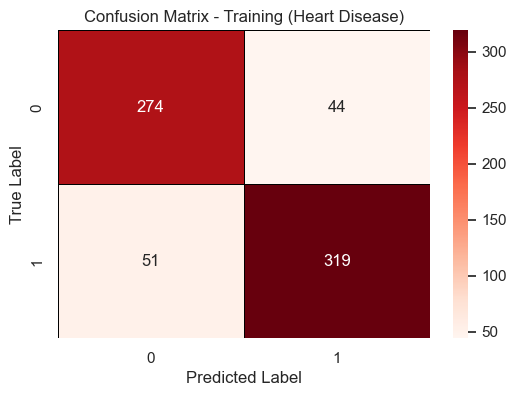


Evaluasi Test: 
[[ 73  19]
 [ 16 122]]
              precision    recall  f1-score   support

           0       0.82      0.79      0.81        92
           1       0.87      0.88      0.87       138

    accuracy                           0.85       230
   macro avg       0.84      0.84      0.84       230
weighted avg       0.85      0.85      0.85       230



In [34]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# --- EVALUASI DATA TRAINING ---
cm_train = confusion_matrix(y_train, y_pred_train)

print("Evaluasi Training: ")
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_train,
    annot=True,
    fmt='d',
    cmap='Reds',
    linewidths=0.5,
    linecolor='black',
    xticklabels=[0, 1],
    yticklabels=[0, 1]
)
plt.title("Confusion Matrix - Training (Heart Disease)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()
plt.close()

# --- EVALUASI DATA TEST ---
cm_test = confusion_matrix(y_test, y_pred_test)
print("\nEvaluasi Test: ")
print(cm_test)
print(classification_report(y_test, y_pred_test, zero_division=0)) 
#202431029_Jonathan Juan Setyanto

In [35]:
# Memasukkan 11 nilai fitur sampel [Age, Sex, ChestPainType, RestingBP, Cholesterol, FastingBS, RestingECG, MaxHR, ExerciseAngina, Oldpeak, ST_Slope]
new_patient = np.array([[40, 1, 0, 140, 289, 0, 1, 172, 0, 0.0, 2]])
prediction = model.predict(new_patient)
print("Hasil prediksi penyakit jantung:", prediction[0]) #202431029_Jonathan Juan Setyanto

Hasil prediksi penyakit jantung: 0


C:\Users\jjset\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


# DECISION TREE

In [36]:
x = df.drop(['HeartDisease'], axis=1) #karna pakenya fitur numerik buat X (independent), axis = 1 buat yg di drop
#202431029_Jonathan Juan Setyanto

In [37]:
x
#202431029_Jonathan Juan Setyanto

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,40,1,1,140,289,0,1,172,0,0.0,2
1,49,0,2,160,180,0,1,156,0,1.0,1
2,37,1,1,130,283,0,2,98,0,0.0,2
3,48,0,0,138,214,0,1,108,1,1.5,1
4,54,1,2,150,195,0,1,122,0,0.0,2
...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,3,110,264,0,1,132,0,1.2,1
914,68,1,0,144,193,1,1,141,0,3.4,1
915,57,1,0,130,131,0,1,115,1,1.2,1
916,57,0,1,130,236,0,0,174,0,0.0,1


In [38]:
y = df['HeartDisease'] #y nya atau targetnya atau dependentnya si HeartDisease, gausah pake axis karna ga nge drop
y
#202431029_Jonathan Juan Setyanto

0      0
1      1
2      0
3      1
4      0
      ..
913    1
914    1
915    1
916    1
917    0
Name: HeartDisease, Length: 918, dtype: int64

In [39]:
from sklearn.model_selection import train_test_split #splitting sblm buat model. misah data uji sama data latih dari dataset

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, random_state=0)
#202431029_Jonathan Juan Setyanto

In [40]:
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier() #inisialisasi model Decison tree
classifier.fit(x_train, y_train) #training model
#202431029_Jonathan Juan Setyanto

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

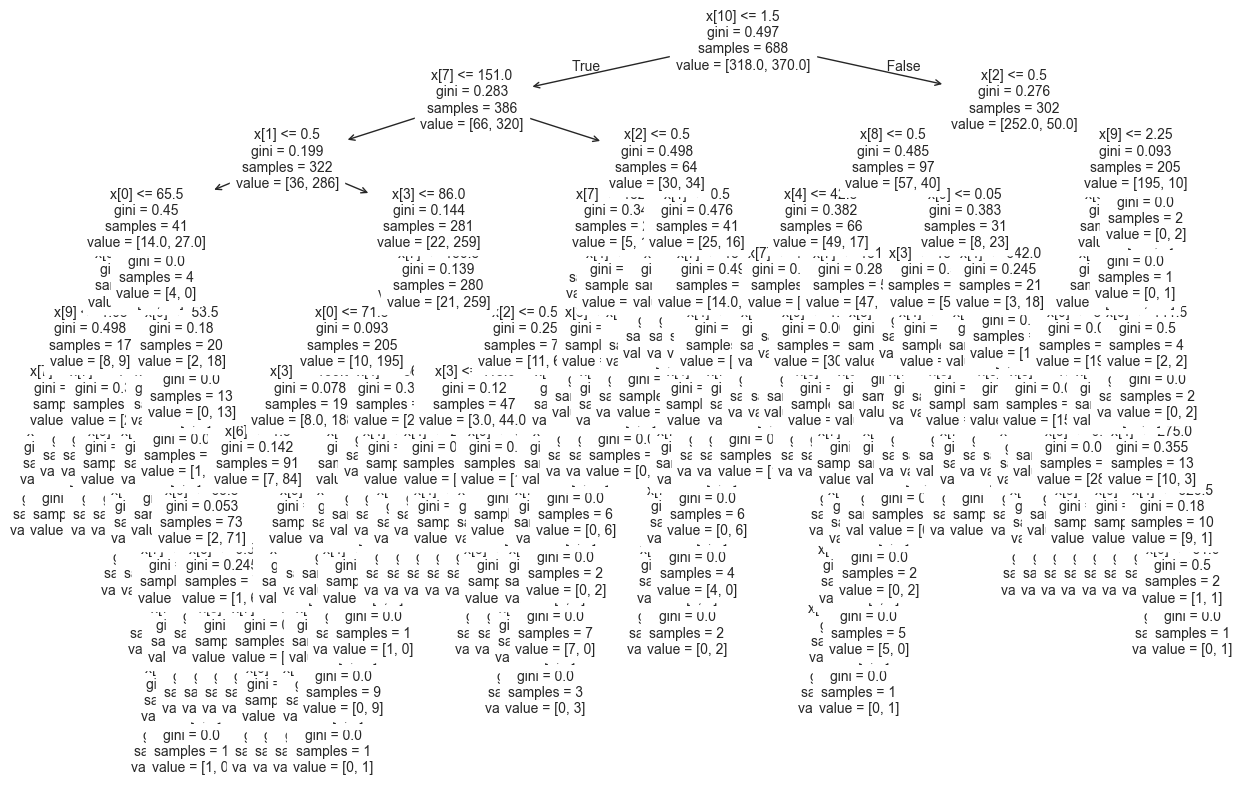

In [41]:
from sklearn import tree #buat pohon keputusannya

plt.subplots(figsize = (15,10)) #ukuran kanvas buat pohonya (seluruh diagram ya, bukan kotak cabangnya)
tree.plot_tree(classifier, fontsize = 10) #buat pohon dari model yg dah dibuat, ukuran fontnya 10
plt.show()
#202431029_Jonathan Juan Setyanto

In [42]:
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier(criterion ='entropy', max_depth=5) #inisialisasi model Decison tree memakai entropy
classifier.fit(x_train, y_train) #training model
#202431029_Jonathan Juan Setyanto

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

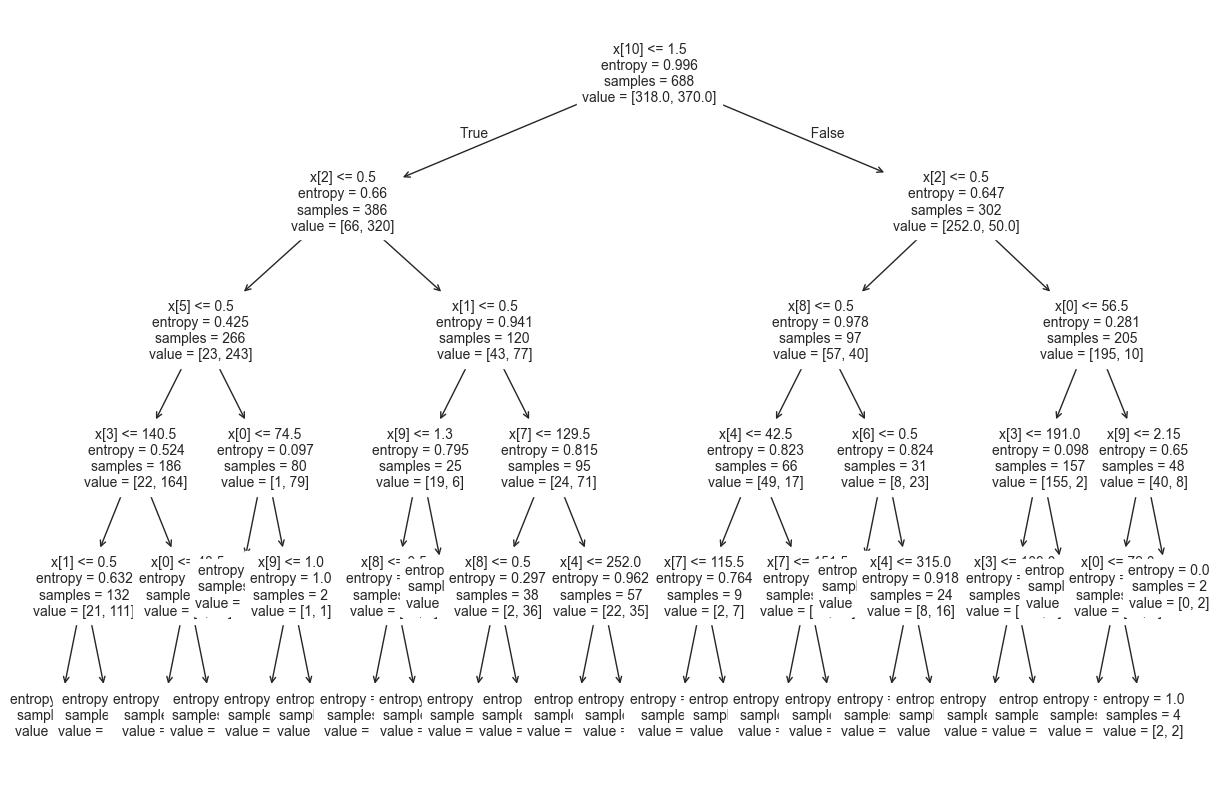

In [43]:
from sklearn import tree

plt.subplots(figsize = (15,10)) #ukuran kanvas buat pohonya (seluruh diagram ya, bukan kotak cabangnya)
tree.plot_tree(classifier, fontsize = 10) #buat pohon dari model yg dah dibuat, ukuran fontnya 10
plt.show()
#202431029_Jonathan Juan Setyanto

In [44]:
depth = classifier.get_depth() #buat tahu depth/kedalaman dari tree yg kita buat berapa (berguna kalo turunannya banyak)
depth
#202431029_Jonathan Juan Setyanto

5

In [45]:
from sklearn.metrics import accuracy_score #ngecek akurasi dari model

y_pred = classifier.predict(x_test) #prediksi y pakai x nya itu dari x uji/ x_test yg 0.25 itu
akurasi = accuracy_score(y_test, y_pred) #ngecek akurasi bandingin dari y_test (dari dataset) sama y_pred (dari hasil baris diatas)
print(akurasi) #ngeprint, hasilnya pasti 0.xxx bacanya xx%
#202431029_Jonathan Juan Setyanto

0.8304347826086956


In [46]:
# data acak dicek sbg x buat liat hasil y nya apa (11 nilai fitur sesuai kolom dataset heart disease)
y_pred = classifier.predict([[40, 1, 0, 140, 289, 0, 1, 172, 0, 0.0, 2]]) 
print(y_pred)
#202431029_Jonathan Juan Setyanto

[0]


C:\Users\jjset\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
